## Collaborative Machine Learning Project Using Jupyter Notebook
### Context: Part 2 of Statistical Foundations for Cybersecurity course
### Instructor: Mme F. Saïd
### Students: Tanguy Stekke & Atwam Emmanuel 

### This jupyter notebook will be divided in the following parts:
- Data Preprocessing
- Exploratory Data Analysis
- Model selection
- Model training and tuning
- Model evaluation

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, MinMaxScaler, OrdinalEncoder, RobustScaler
from yellowbrick.cluster import SilhouetteVisualizer, KElbowVisualizer, InterclusterDistance
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import resample
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA as SklearnPCA
from yellowbrick.features import PCA as YellowbrickPCA
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import silhouette_score, mean_squared_error, r2_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score
import category_encoders as ce  # For Binary Encoding and Leave-One-Out Encoding
from scipy.stats import pearsonr, stats
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import scipy.cluster.hierarchy as sch
from imblearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from myfunctions import *
pd.options.mode.chained_assignment = None

import warnings

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    message=".*Setting an item of incompatible dtype is deprecated.*"
)

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    message=".* DataConversionWarning*"
)

  pd.options.mode.chained_assignment = None


Dataset from Kaggle: https://www.kaggle.com/datasets/lainguyn123/student-performance-factors/data

# Data Preprocessing Steps
Here are the data preprocessing that are going to be used in the context of the student performance prediction. 

### 1. Data Cleaning
- **Handling Missing Values**:  
  - Methods: Deletion, Imputation (mean, median, predictive models), or algorithms supporting missing values (e.g., Decision Trees). Using for example: df.dropna() and df.fillna(df.mean())

- **Inconsistencies**:  
  - Correct duplicates and errors.

- **Data Encoding**: 
  - **Categorical Data**: Apply One-Hot Encoding or Label Encoding.

### 2. Data Transformation
- **Normalization and Standardization**: Scale data for algorithms sensitive to scale.
- **Scaling**: Ensure consistent scales for gradient-based algorithms.

### 3. Data Reduction
- **Dimensionality Reduction**: Use PCA or similar methods.
- **Feature Selection**: Retain only informative features.

### 5. Data Integration
- Merge datasets while ensuring consistency in formatting and values.

### 6. Feature Engineering
- Create new features that enhance the dataset’s representation.

### 7. Data Splitting
- Divide data into training, validation, and test sets to prevent overfitting.

##############################################
### 1. Data cleaning
##############################################

In [2]:
df = pd.read_csv("./archive/StudentPerformanceFactors.csv", sep=',')
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [3]:
target_name = "Exam_Score"

### Removing missing values:
They are 235 missing values for 229 rows which amounts for 3% of the rows that contains missing values. We tried to replace the missings values by the means of the columns but we got worse results in our models that when just dropping the data. It can be explain by the fact that the missing values are a small proportion of the data set and distributed randomly.

In [4]:
missing_values = df.isnull().sum()
print(missing_values.sum())

df = df.dropna()
print(f"Shape of df: {df.shape}")

235
Shape of df: (6378, 20)


### Encoding:

For our dataset, we chose Label Encoding for binary variables like Extracurricular_Activities, Internet_Access, Learning_Disabilities, and Gender because they have two distinct categories (Yes/No, Male/Female), and Label Encoding converts them to numeric values (1 and 0). For ordinal variables such as Parental_Involvement, Access_to_Resources, Motivation_Level, Teacher_Quality, and Family_Income. We used Ordinal Encoding because these variables have a clear ranking (e.g., Low < Medium < High). 

In [5]:
# 1. Ordinal Encoding for columns with a natural order
ordinal_columns = ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level',
                   'Family_Income', 'Teacher_Quality', 'Peer_Influence', 'Distance_from_Home', 'Parental_Education_Level']

ordinal_categories = [
    ['Low', 'Medium', 'High'],  # Parental_Involvement
    ['Low', 'Medium', 'High'],  # Access_to_Resources
    ['Low', 'Medium', 'High'],  # Motivation_Level
    ['Low', 'Medium', 'High'],  # Family_Income
    ['Low', 'Medium', 'High'],  # Teacher_Quality
    ['Negative', 'Neutral', 'Positive'],  # Peer_Influence
    ['Near', 'Moderate', 'Far'],  # Distance_from_Home
    ['High School', 'College', 'Postgraduate']  # Parental_Education_Level
]

# Apply Ordinal Encoding for each column and ensure proper type conversion
for column, categories in zip(ordinal_columns, ordinal_categories):
    ordinal_encoder = OrdinalEncoder(categories=[categories])
    df[column] = ordinal_encoder.fit_transform(df[[column]])
    df[column] = df[column].astype('int64') 


#-----------
# 2. Label Encoding for binary categorical columns (Yes/No, Male/Female), ...
binary_columns = ['Extracurricular_Activities', 'Internet_Access', 'Learning_Disabilities', 'Gender', 'School_Type']

label_encoder = LabelEncoder()

# Loop over the binary columns and apply LabelEncoder to each
for column in binary_columns:
    df[column] = label_encoder.fit_transform(df[[column]])
    df[column] = df[column].astype('int64')  


c:\Users\H2O\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.py:114: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\H2O\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.py:114: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\H2O\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.py:114: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\H2O\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.py:114: D

### Remove duplicate data

In [6]:
duplicates = df.duplicated()
if duplicates.any():
    print(f"Number of duplicate rows: {duplicates.sum()}")
    df = df.drop_duplicates()
    print("Duplicates removed.")
else:
    print("No duplicate rows found.")

No duplicate rows found.


In [7]:
# Create a DataFrame for the target
target_df = pd.DataFrame()

target_df[target_name] = df[target_name]

print(f"Shape of df: {df.shape}")
print(f"Shape of target: {target_df.shape}")

Shape of df: (6378, 20)
Shape of target: (6378, 1)


#############################################################
# Exploratory Data Analysis
#############################################################

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6378 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6378 non-null   int64
 1   Attendance                  6378 non-null   int64
 2   Parental_Involvement        6378 non-null   int64
 3   Access_to_Resources         6378 non-null   int64
 4   Extracurricular_Activities  6378 non-null   int64
 5   Sleep_Hours                 6378 non-null   int64
 6   Previous_Scores             6378 non-null   int64
 7   Motivation_Level            6378 non-null   int64
 8   Internet_Access             6378 non-null   int64
 9   Tutoring_Sessions           6378 non-null   int64
 10  Family_Income               6378 non-null   int64
 11  Teacher_Quality             6378 non-null   int64
 12  School_Type                 6378 non-null   int64
 13  Peer_Influence              6378 non-null   int64
 14  Physical_Acti

In [9]:
df.describe().round(1)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
count,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0,6378.0
mean,20.0,80.0,1.1,1.1,0.6,7.0,75.1,0.9,0.9,1.5,0.8,1.2,0.7,1.2,3.0,0.1,0.7,0.5,0.6,67.3
std,6.0,11.6,0.7,0.7,0.5,1.5,14.4,0.7,0.3,1.2,0.7,0.6,0.5,0.8,1.0,0.3,0.8,0.7,0.5,3.9
min,1.0,60.0,0.0,0.0,0.0,4.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,55.0
25%,16.0,70.0,1.0,1.0,0.0,6.0,63.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,2.0,0.0,0.0,0.0,0.0,65.0
50%,20.0,80.0,1.0,1.0,1.0,7.0,75.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,0.0,1.0,0.0,1.0,67.0
75%,24.0,90.0,2.0,2.0,1.0,8.0,88.0,1.0,1.0,2.0,1.0,2.0,1.0,2.0,4.0,0.0,1.0,1.0,1.0,69.0
max,44.0,100.0,2.0,2.0,1.0,10.0,100.0,2.0,1.0,8.0,2.0,2.0,1.0,2.0,6.0,1.0,2.0,2.0,1.0,101.0


### Analyzing correlations among explanatory variables

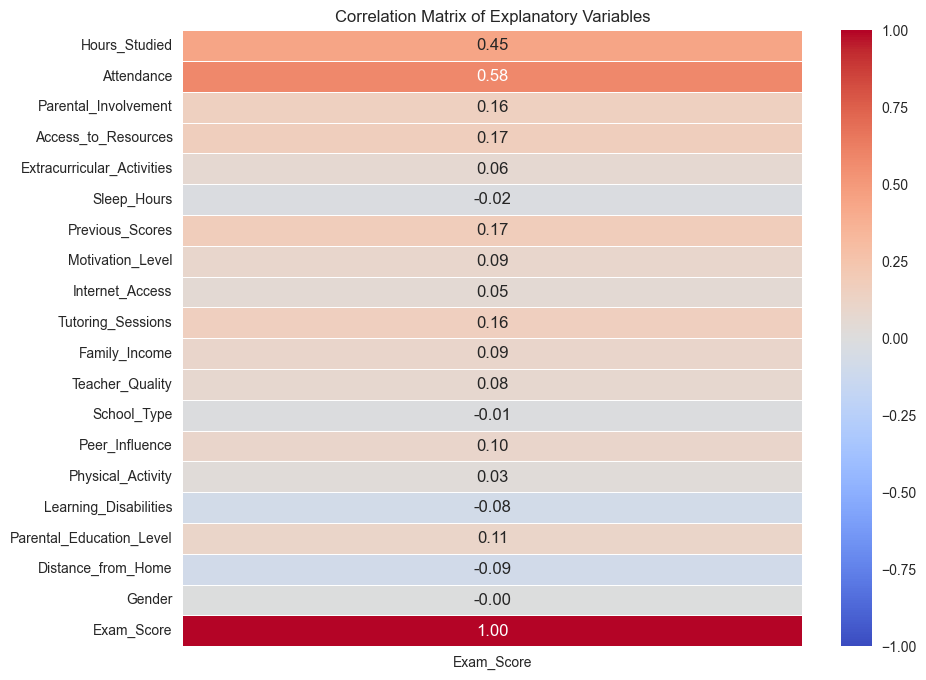

In [10]:
num = df
plt.figure(figsize=(10, 8))
sns.heatmap(num.corr()[['Exam_Score']], annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Matrix of Explanatory Variables")
plt.show()

Show how strong the factors are related to the Exam_Score. 

High correlations:
Both attendance and hours studied have the strongest positive correlations with exam scores. Which indicate that students with better attendance and hours studied tend to perform better.

Weak correlations:
Parental Involvement, access to ressources, previous scores and tutoring sessions have non neglibable correlations, that are still weak but can still used.

Near zero correlations:
Gender, physical activity,... have weak and negligible correlations with exams scores.

### How does attendance influence exam score ?

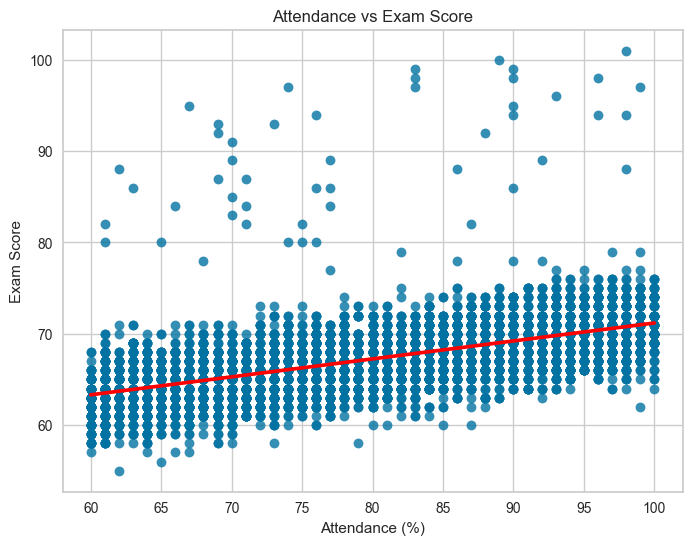

Correlation between Attendance and Exam Score: 0.58


In [11]:
plt.figure(figsize=(8, 6))
sns.regplot(x='Attendance', y='Exam_Score',  data=df, scatter_kws={'s': 50}, line_kws={'color': 'red'})
plt.title("Attendance vs Exam Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.show()
correlation = df['Attendance'].corr(df['Exam_Score'])
print(f"Correlation between Attendance and Exam Score: {correlation:.2f}")

Visualize the relationship between attendance and exam score, a positive trend is visible as attendance increase so do the exam score.

### How Does Internet Access Impact Exam Scores?

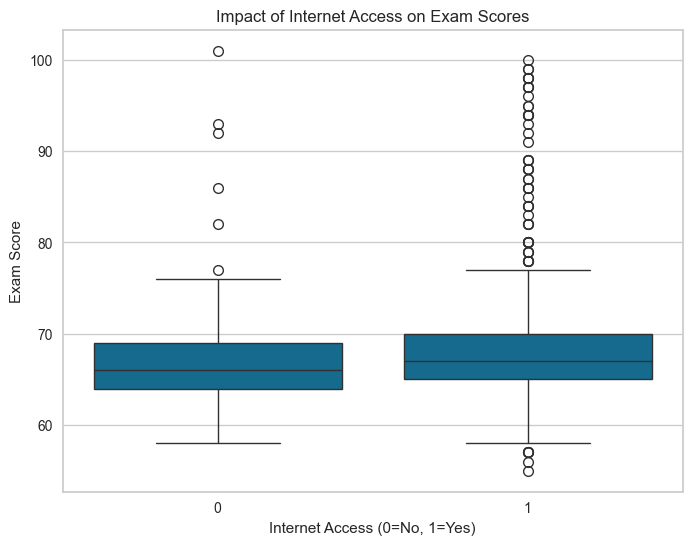

Correlation between Attendance and Exam Score: 0.05


In [12]:
plt.figure(figsize=(8, 6))
sns.boxplot(x=df["Internet_Access"], y=df["Exam_Score"])
plt.title("Impact of Internet Access on Exam Scores")
plt.xlabel("Internet Access (0=No, 1=Yes)")
plt.ylabel("Exam Score")
plt.show()
correlation = df['Internet_Access'].corr(df['Exam_Score'])
print(f"Correlation between Attendance and Exam Score: {correlation:.2f}")

Compares the distribution of exam scores for students with and without internet access.
Insights:
- Students with internet access (1 = Yes) generally perform slightly better than those without it (0 = No).
- However, the difference in medians is very slight, and there is significant overlap between the two groups.
- Outliers are more present in the internet access group, indicating more variability in performance of the one who have internet access.

### Impact of Familly Income on Exam Scores

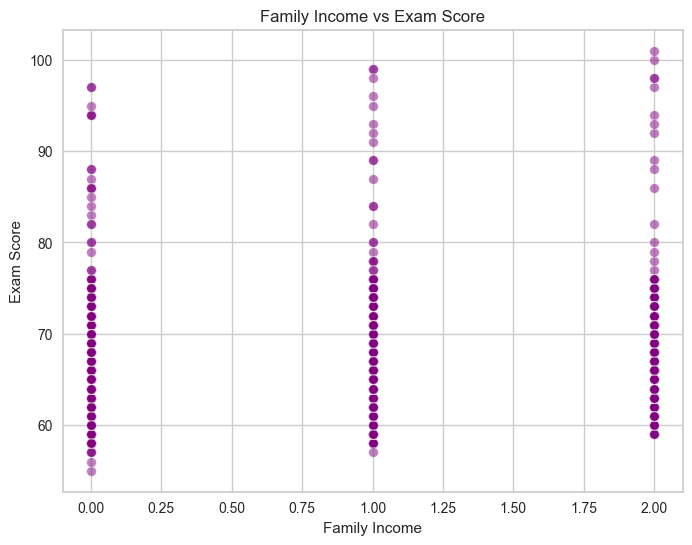

Correlation between Attendance and Exam Score: 0.09


In [13]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df["Family_Income"], y=df["Exam_Score"], alpha=0.5, color='purple')
plt.title("Family Income vs Exam Score")
plt.xlabel("Family Income")
plt.ylabel("Exam Score")
plt.show()
correlation = df['Family_Income'].corr(df['Exam_Score'])
print(f"Correlation between Attendance and Exam Score: {correlation:.2f}")

###  Gender Distribution and Exam Performance

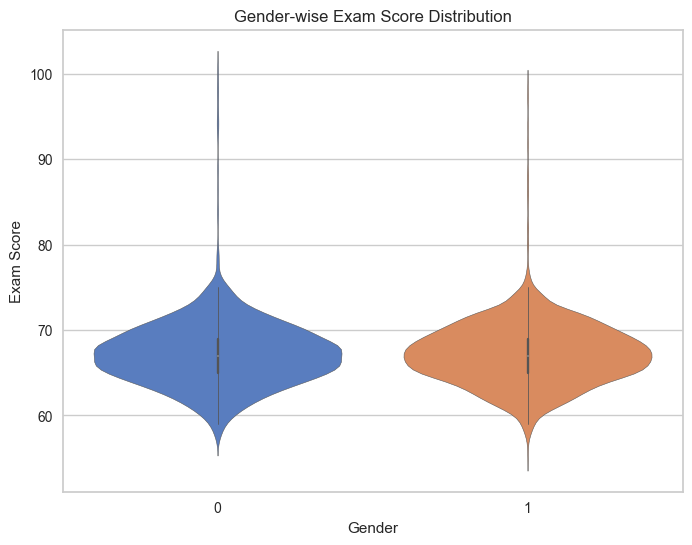

Correlation between Attendance and Exam Score: -0.00


In [14]:
plt.figure(figsize=(8, 6))
sns.violinplot(x="Gender", y="Exam_Score", data=df, hue="Gender", legend=False, palette="muted")
plt.title("Gender-wise Exam Score Distribution")
plt.xlabel("Gender")
plt.ylabel("Exam Score")
plt.show()
correlation = df['Gender'].corr(df['Exam_Score'])
print(f"Correlation between Attendance and Exam Score: {correlation:.2f}")

Gender score distribution, both genders have very simiar distributions with median score around 70. Gender 0 shows more variability, gender 1 has a denser clustering around the median. (0=Male, 1=Female)

### Relationship Between Hours Studied and Exam Scores

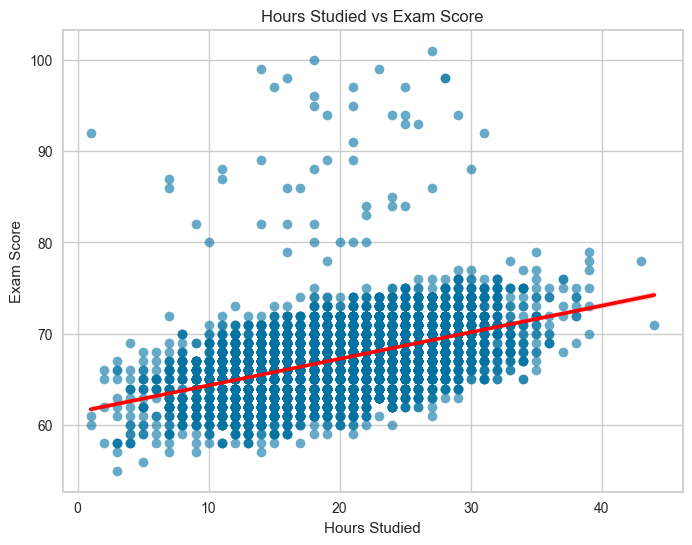

In [15]:
plt.figure(figsize=(8, 6))
sns.regplot(x=df["Hours_Studied"], y=df["Exam_Score"], scatter_kws={"alpha":0.6}, line_kws={"color":"red"})
plt.title("Hours Studied vs Exam Score")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.show()

There seems to be a pretty high correlation beetwen the Exam score and the number of hours studied. The graph is very visualy very similar to the attendance vs Exam score. This suggests that the hours studided is another explanatory variable in prediction exam scores.

### EDA conclusions
The EDA provided instights into the dataset. We were able to identify the key factos that influence exam performance. Additional factors like family income, parental involvement, and internet access also have some impact, though weaker. The other factors can be dropped in the futur model without having an impact on the results. Dropping those factors will improve the performances of the model. The next steps involve finding if data reduction is possible in our data and applying regression and classification models to predict exam scores and categorize students based on their results.

##############################################
## 2. Data Transformation
##############################################

In [16]:
# Standardize the data  (removing the median and centering) using sklearn robust function to handle better
scaler = StandardScaler()
dfs = scaler.fit_transform(df)

##############################################
## 3. Data Reduction
##############################################

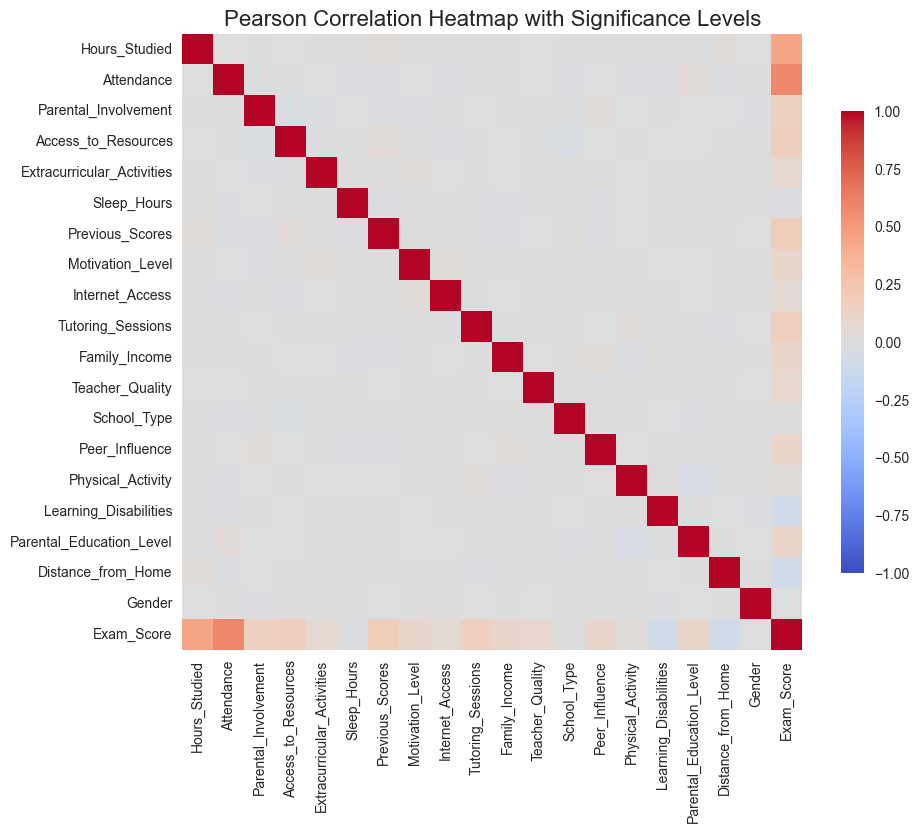

In [17]:
######################################################
# Dimensionality Reduction with PCA
######################################################

# Calculate Pearson correlations and their significance levels
def calculate_pvalues(df):
    pvalues = pd.DataFrame(np.ones((df.shape[1], df.shape[1])), columns=df.columns, index=df.columns)
    for col1 in df.columns:
        for col2 in df.columns:
            if col1 != col2:
                _, pvalue = pearsonr(df[col1], df[col2])
                pvalues.loc[col1, col2] = pvalue
    return pvalues

corr = df.corr()
pvalues = calculate_pvalues(df)

# Define function to annotate correlation heatmap with significance
def correlation_significance_string(corr_value, pvalue):
    if pvalue < 0.001:
        significance = "***"
    elif pvalue < 0.01:
        significance = "**"
    elif pvalue < 0.05:
        significance = "*"
    else:
        significance = ""
    return f"{corr_value:.2f}{significance}"

annot = corr.copy()
for i in annot.columns:
    for j in annot.index:
        annot.loc[j, i] = correlation_significance_string(corr.loc[j, i], pvalues.loc[j, i])

# Plot heatmap with correlation and significance levels
plt.figure(figsize=(10, 8))
sns.heatmap(corr, fmt='', cmap='coolwarm', vmin=-1, vmax=1, center=0, 
            cbar_kws={"shrink": .75}, annot_kws={"size": 12})
plt.title('Pearson Correlation Heatmap with Significance Levels', fontsize=16)
plt.show()


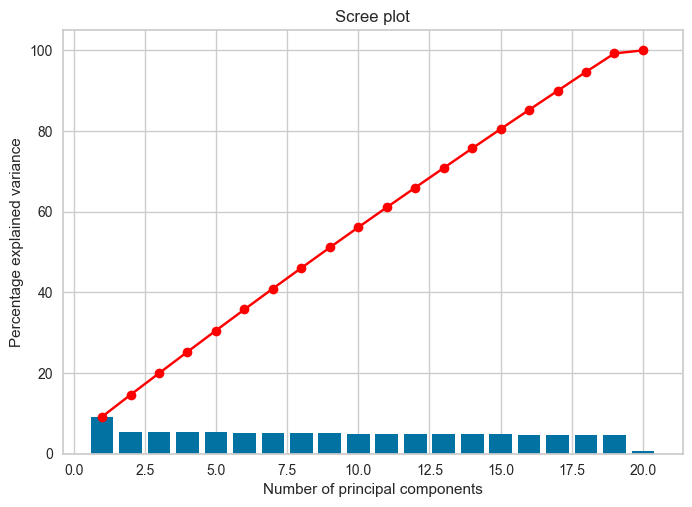

In [18]:
# Full PCA model
pca = SklearnPCA()
principalComponents = pca.fit_transform(dfs)

display_scree_plot(pca)

PCA is not meaningful in this context because the variables lack significant correlations with one another, and only some of them show a meaningful relationship with the exam score.

#############################################################
# Model selection
############################################################# 

From the PCA and EDA and the characteristics of the target variable Exam_score, which is continuous we identified two primary machine tasks that we will explore:
The dataset contains many numerical features with correlations with the features and the target, regression models are suitable for prediction the exact score, classification could on the other hand, categorize students into performance groups. The low correlations among the features indic that they are independant which reduce the risk of multicollinerarity in regression. Features with high correlation to Exam_Score (e.g., Hours_Studied, Attendance, Previous_Scores) will significantly influence our regression model.

Supervised Learning (Regression) | Linear Regressions VS Random Forest Regression (RFR)

Supervised Learning (Classficiation) | Random Forest Classification

#############################################################
# Model training and tuning
############################################################# 

## Supervised learning: Random Forest Regression VS Linear Regression

In [19]:
# As seen in the DAE, we can safely remove those columns without reducing the accuracy of the models.
df = df.drop(columns="Sleep_Hours")
df = df.drop(columns="School_Type")
df = df.drop(columns="Internet_Access")
df = df.drop(columns="Gender")
df = df.drop(columns="Physical_Activity")

In [20]:
y = target_df.values.ravel()

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns=target_name), y, test_size=0.2, random_state=42)

rfr = RandomForestRegressor(random_state=0)

# Here are the best hyperparameters found from a bigger param_grids
param_grid = {
    'n_estimators': [200],
    'max_depth': [20],
    'min_samples_split': [5],
    'min_samples_leaf': [2]
}
grid_search = GridSearchCV(estimator=rfr, param_grid=param_grid, cv=5, verbose=2, n_jobs=-1)
grid_search.fit(X_train, y_train)

# Get the best parameters and evaluate the model
best_rf = grid_search.best_estimator_

# Predict using the best model
y_pred = best_rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Print regression metrics
print("Best Parameters:", grid_search.best_params_)
print(f"Mean Squared Error: {mse}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R^2 Score: {r2}")

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best Parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Mean Squared Error: 5.373124478897329
Root Mean Squared Error: 2.3180001032996804
R^2 Score: 0.6542240745077682


In [21]:
y = target_df.values.ravel()

X_train, X_test, y_train, y_test = train_test_split(df.drop(columns=target_name), y, test_size=0.2, random_state=42)

linear_reg = LinearRegression()

linear_reg.fit(X_train, y_train)

# Predict on the test data
y_pred = linear_reg.predict(X_test)

# Evaluate performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)


print(f"Mean Squared Error: {mse}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R^2 Score: {r2}")


Mean Squared Error: 4.237461730449282
Root Mean Squared Error: 2.058509589593714
R^2 Score: 0.7273072199725577


The Linear Regression model is the best in this case, as it achieves a higher R² score of 0.7273 compared to the Random Forest model's R² score of 0.6542. Additionally, Linear Regression has a lower Mean Squared Error (MSE) of 4.2375 (vs 5.3731 for Random Forest), indicating better predictive accuracy. While Random Forest provides feature importance values, the overall performance of Linear Regression model is better based on these metrics.

##  Supervised learning: Random Forest Classifier

In [22]:
# Calculate Mean, Standard Deviation, and Percentiles in order to have 3 category
# Low results, Medium results and high results.
mean_score = df[target_name].mean()
std_dev_score = df[target_name].std()
percentile_25 = np.percentile(df[target_name], 25)
percentile_50 = np.percentile(df[target_name], 50)
percentile_75 = np.percentile(df[target_name], 75)

def categorize_exam_score(stat_score):
    if stat_score < percentile_25:
        return 'Low'
    elif percentile_25 <= stat_score < percentile_75:
        return 'Medium'
    else:
        return 'High'

In [23]:
df['Exam_Score_Category'] = df[target_name].apply(categorize_exam_score)
df =df.drop(columns=target_name)

#Count the Number of Students in Each Category
category_counts = df['Exam_Score_Category'].value_counts()

print("Number of students in each category:")
print(category_counts)

# Split Data for Classification
X = df.drop(columns=["Exam_Score_Category"], axis=1)
y = df['Exam_Score_Category']


Number of students in each category:
Exam_Score_Category
Medium    2802
High      2180
Low       1396
Name: count, dtype: int64


In [24]:

# Split Data into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

rf_classifier = RandomForestClassifier(random_state=42)
rf_classifier.fit(X_train, y_train)

# Predict on test data
rf_predictions = rf_classifier.predict(X_test)

accuracy = accuracy_score(y_test, rf_predictions)
precision = precision_score(y_test, rf_predictions, average='weighted')  # Use 'macro' or 'micro' for multi-class if needed
recall = recall_score(y_test, rf_predictions, average='weighted')  # 'weighted' averages across classes
f1 = f1_score(y_test, rf_predictions, average='weighted') 

# Evaluate Random Forest Classifier
print("\nRandom Forest Classifier Results:")

print(classification_report(y_test, rf_predictions))
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1-Score: {f1}")

print("Confusion Matrix:\n", confusion_matrix(y_test, rf_predictions))


Random Forest Classifier Results:
              precision    recall  f1-score   support

        High       0.90      0.80      0.85       455
         Low       0.88      0.72      0.79       283
      Medium       0.74      0.88      0.80       538

    accuracy                           0.81      1276
   macro avg       0.84      0.80      0.81      1276
weighted avg       0.83      0.81      0.81      1276

Accuracy: 0.8142633228840125
Precision: 0.8267340332405074
Recall: 0.8142633228840125
F1-Score: 0.8149285496765866
Confusion Matrix:
 [[363   3  89]
 [  0 203  80]
 [ 40  25 473]]


The Random Forest Classifier achieved an overall accuracy of 81.43%, effectively categorizing students into "High," "Medium," and "Low" exam score categories. The model demonstrated precision of 0.90 (High) and 0.74 (Medium) and recall of 0.80 (High) and 0.88 (Medium). However, the "Low" category showed slightly lower recall (0.72), indicating some misclassification. The weighted average f1-score is 0.81, reflecting a balanced performance across all categories. The confusion matrix reveals that most misclassifications occurred between adjacent categories, likely due to overlapping scores near the statistical thresholds.